<a href="https://colab.research.google.com/github/SaMaRXXX/hate-speech-detector/blob/main/Hate_Speech_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
%%capture
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import train_test_split

import nltk
import string
import warnings
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud

import tensorflow as tf
from tensorflow import keras
from keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

nltk.download('stopwords')
nltk.download('omw-1.4')
nltk.download('wordnet')
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('/content/Dataset---Hate-Speech-Detection-using-Deep-Learning (1).csv')
df.head()

,class,tweet
0,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [ ]:
df.shape

(24783, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   class   24783 non-null  int64 
 1   tweet   24783 non-null  object
dtypes: int64(1), object(1)
memory usage: 387.4+ KB


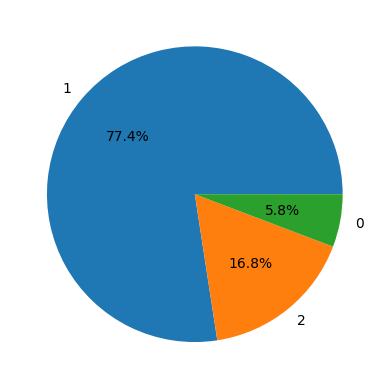

In [ ]:
plt.pie(df['class'].value_counts().values,
		labels = df['class'].value_counts().index,
		autopct='%1.1f%%')
plt.show()

In [20]:
import string

if 'df' not in locals():
    try:
        df = pd.read_csv('/content/Dataset---Hate-Speech-Detection-using-Deep-Learning (1).csv')
    except FileNotFoundError:
        print("Dataset file not found at the specified path. Please upload it or ensure 'df' is loaded.")

if 'df' in locals():
    df['tweet'] = df['tweet'].str.lower()
    punctuations_list = string.punctuation
    def remove_punctuations(text):
        temp = str.maketrans('', '', punctuations_list)
        return text.translate(temp)
    df['tweet'] = df['tweet'].apply(lambda x: remove_punctuations(x))
    print(df.head())
else:
    print("Variable 'df' is not defined.")

Dataset file not found at the specified path. Please upload it or ensure 'df' is loaded.
Variable 'df' is not defined.


In [21]:
if 'df' not in locals():
    try:
        df = pd.read_csv('/content/Dataset---Hate-Speech-Detection-using-Deep-Learning (1).csv')
    except FileNotFoundError:
        pass

def remove_stopwords(text):
    stop_words = stopwords.words('english')
    imp_words = []
    for word in str(text).split():
        if word not in stop_words:
            lemmatizer = WordNetLemmatizer()
            lemmatizer.lemmatize(word)
            imp_words.append(word)
    output = " ".join(imp_words)
    return output

if 'df' in locals():
    df['tweet'] = df['tweet'].apply(lambda text: remove_stopwords(text))
    print(df.head())
else:
    print("Variable 'df' is not defined.")

Variable 'df' is not defined.


In [22]:
if 'df' not in locals():
    try:
        df = pd.read_csv('/content/Dataset---Hate-Speech-Detection-using-Deep-Learning (1).csv')
    except FileNotFoundError:
        pass

def plot_word_cloud(data, typ):
    email_corpus = " ".join(data['tweet'])
    plt.figure(figsize=(10, 10))
    wc = WordCloud(max_words=100,
                  width=200,
                  height=100,
                  collocations=False).generate(email_corpus)
    plt.title(f'WordCloud for {typ} emails.', fontsize=15)
    plt.axis('off')
    plt.imshow(wc)
    plt.show()
    print()

if 'df' in locals():
    plot_word_cloud(df[df['class'] == 2], typ='Neither')
else:
    print("Variable 'df' is not defined.")

Variable 'df' is not defined.


In [ ]:
class_2 = df[df['class'] == 2]
class_1 = df[df['class'] == 1].sample(n=3500)
class_0 = df[df['class'] == 0]

balanced_df = pd.concat([class_0, class_0, class_0, class_1, class_2], axis=0)

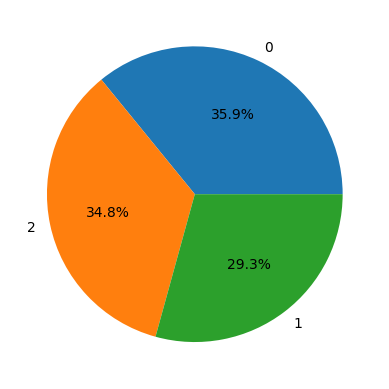

In [ ]:
plt.pie(balanced_df['class'].value_counts().values,
		labels=balanced_df['class'].value_counts().index,
		autopct='%1.1f%%')
plt.show()

In [ ]:
features = balanced_df['tweet']
target = balanced_df['class']

X_train, X_val, Y_train, Y_val = train_test_split(features,
												target,
												test_size=0.2,
												random_state=22)
X_train.shape, X_val.shape

((9562,), (2391,))

In [ ]:
Y_train = pd.get_dummies(Y_train)
Y_val = pd.get_dummies(Y_val)
Y_train.shape, Y_val.shape

((9562, 3), (2391, 3))

In [ ]:
max_words = 5000
max_len = 100

token = Tokenizer(num_words=max_words,
				lower=True,
				split=' ')

token.fit_on_texts(X_train)

In [23]:
if 'X_train' not in locals():
    from sklearn.model_selection import train_test_split
    if 'balanced_df' not in locals():
        if 'df' not in locals():
            try:
                df = pd.read_csv('/content/Dataset---Hate-Speech-Detection-using-Deep-Learning (1).csv')
            except FileNotFoundError:
                pass
        if 'df' in locals():
            class_2 = df[df['class'] == 2]
            class_1 = df[df['class'] == 1].sample(n=3500, random_state=22)
            class_0 = df[df['class'] == 0]
            balanced_df = pd.concat([class_0, class_0, class_0, class_1, class_2], axis=0)
    if 'balanced_df' in locals():
        features = balanced_df['tweet']
        target = balanced_df['class']
        X_train, X_val, Y_train, Y_val = train_test_split(features, target, test_size=0.2, random_state=22)

if 'X_train' in locals():
    max_words = 5000
    token = Tokenizer(num_words=max_words, lower=True, split=' ')
    token.fit_on_texts(X_train)
    Training_seq = token.texts_to_sequences(X_train)
    Training_pad = pad_sequences(Training_seq, maxlen=50, padding='post', truncating='post')
    Testing_seq = token.texts_to_sequences(X_val)
    Testing_pad = pad_sequences(Testing_seq, maxlen=50, padding='post', truncating='post')
else:
    print("Variables not initialized. Please ensure the dataset is loaded.")

Variables not initialized. Please ensure the dataset is loaded.


In [13]:
from tensorflow import keras
from tensorflow.keras import layers

max_words = 10000
max_len = 100

model = keras.models.Sequential([
    layers.Embedding(input_dim=max_words, output_dim=32, input_length=max_len),
    layers.Bidirectional(layers.LSTM(16)),
    layers.Dense(512, activation='relu', kernel_regularizer='l1'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax')
])

model.build(input_shape=(None, max_len))

model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 32)             │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 346,755 (1.32 MB)

 Trainable params: 345,731 (1.32 MB)

 Non-trainable params: 1,024 (4.00 KB)

In [ ]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

es = EarlyStopping(patience=3,
				monitor = 'val_accuracy',
				restore_best_weights = True)

lr = ReduceLROnPlateau(patience = 2,
					monitor = 'val_loss',
					factor = 0.5,
					verbose = 0)

In [24]:
if 'X_train' not in locals():
    from sklearn.model_selection import train_test_split
    if 'balanced_df' not in locals():
        if 'df' not in locals():
            try:
                df = pd.read_csv('/content/Dataset---Hate-Speech-Detection-using-Deep-Learning (1).csv')
            except FileNotFoundError:
                pass
        if 'df' in locals():
            class_2 = df[df['class'] == 2]
            class_1 = df[df['class'] == 1].sample(n=3500, random_state=22)
            class_0 = df[df['class'] == 0]
            balanced_df = pd.concat([class_0, class_0, class_0, class_1, class_2], axis=0)
    if 'balanced_df' in locals():
        features = balanced_df['tweet']
        target = balanced_df['class']
        X_train, X_val, Y_train, Y_val = train_test_split(features, target, test_size=0.2, random_state=22)
        import pandas as pd
        Y_train = pd.get_dummies(Y_train)
        Y_val = pd.get_dummies(Y_val)

if 'X_train' in locals():
    tokenizer = Tokenizer(num_words=max_words)
    tokenizer.fit_on_texts(X_train)
    X_train_seq = tokenizer.texts_to_sequences(X_train)
    X_val_seq = tokenizer.texts_to_sequences(X_val)
    from tensorflow.keras.utils import pad_sequences
    X_train_padded = pad_sequences(X_train_seq, maxlen=max_len)
    X_val_padded = pad_sequences(X_val_seq, maxlen=max_len)
    history = model.fit(X_train_padded, Y_train,
                        validation_data=(X_val_padded, Y_val),
                        epochs=50,
                        verbose=1,
                        batch_size=32,
                        callbacks=[lr, es])
else:
    print("Variables not initialized. Please ensure the dataset is loaded.")

Variables not initialized. Please ensure the dataset is loaded.


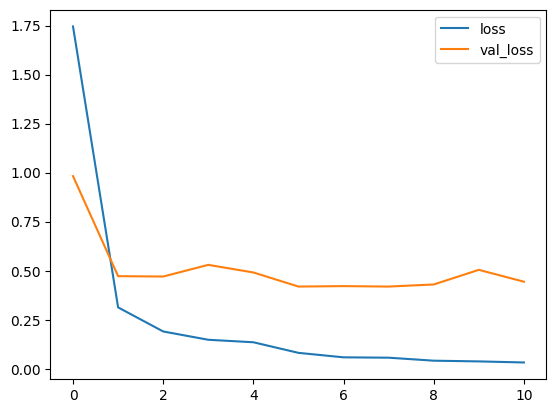

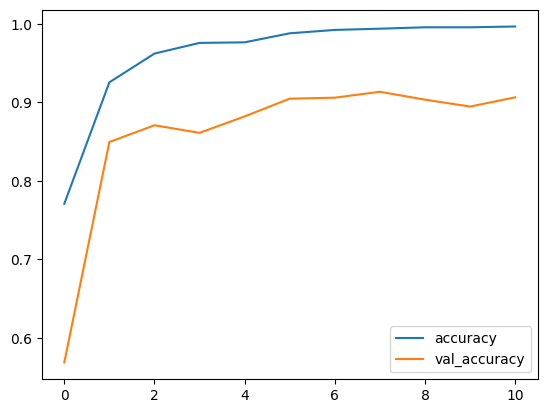

In [ ]:
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot()
history_df.loc[:, ['accuracy', 'val_accuracy']].plot()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(X_val_padded, Y_val)
print(f"Validation Accuracy: {test_acc:.2f}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9142 - loss: 0.4174
Validation Accuracy: 0.91
